# BRCA ST patient G — pan-cancer Hist2Pheno

Andersson et al. *Nat Commun* 2021. HER2ST **G**: patient 23903, sections G1–G3, about 0.69 µm/px. No cell-type ground truth.
Predictions are the pan-cancer **cross-section** checkpoint `D_emph_L2_spatial_pancancer` (L1 / L12 / L2), spatial k=8.

JPEG 72 dpi is not used. µm/px is the 200 µm ST spot pitch. UNI rescales by `mpp/0.5` so the 16 px crop is **8 µm**.

One notebook per patient so the file does not store all 36 slides. Full-resolution PNGs stay in `data/ST/BRCA/pred_pancancer_section/figures/`.

```bash
SAMPLE=G bash code/External_val/BRCA_ST/demo.sh all
```


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA_ST"))

from brca_st_external import (  # noqa: E402
    PRED_ROOT,
    composition_table,
    discover_samples,
    geometry,
    sample_paths,
    ensure_l2_probs,
    plot_spatial,
)

PATIENT = "G"
group = discover_samples(PATIENT)
fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
# Re-run the plot cell after changing these. Files are written only when SAVE_FIGURES is True.
SAVE_FIGURES = False
FIGSIZE = (17.2, 6.6)
DPI = 160
HE_MAX_SIDE = 1400
MARKER_PX = 2.2
print(f"{PATIENT}  n={len(group)}")
for sample in group:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"native16={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}  ({g['mpp_source']})"
    )
    print(f"  pred exists: {sample_paths(sample)['pred'].is_file()}")


G  n=3
HE_BT23903_C1a  mpp=0.6875 µm/px  native16=11.00 µm  after rescale=8.0 µm  scale=1.3750  (ST 200 µm spot pitch (G1))
  pred exists: True
HE_BT23903_C2a  mpp=0.6888 µm/px  native16=11.02 µm  after rescale=8.0 µm  scale=1.3775  (ST 200 µm spot pitch (G2))
  pred exists: True
HE_BT23903_D1a  mpp=0.6895 µm/px  native16=11.03 µm  after rescale=8.0 µm  scale=1.3789  (ST 200 µm spot pitch (G3))
  pred exists: True


## G — composition and spatial labels


===== G L1 =====


fraction                                    mean_conf  \
sample      HE_BT23903_C1a HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a   
class                                                                     
Immune               0.555          0.503          0.491          0.569   
Endothelial          0.290          0.258          0.320          0.487   
Stromal              0.151          0.233          0.168          0.449   
Epithelial           0.004          0.006          0.021          0.453   

                                                       n                 \
sample      HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a HE_BT23903_C2a   
class                                                                     
Immune               0.562          0.564        32031.0        31086.0   
Endothelial          0.487          0.469        16717.0        15972.0   
Stromal              0.471          0.446         8735.0        14435.0   
Epithelial           0.448          0.482          240.0          346.0   

                            
sample      HE_BT23903_D1a  
class                       
Immune             30101.0  
Endothelial        19652.0  
Stromal            10289.0  
Epithelial          1312.0

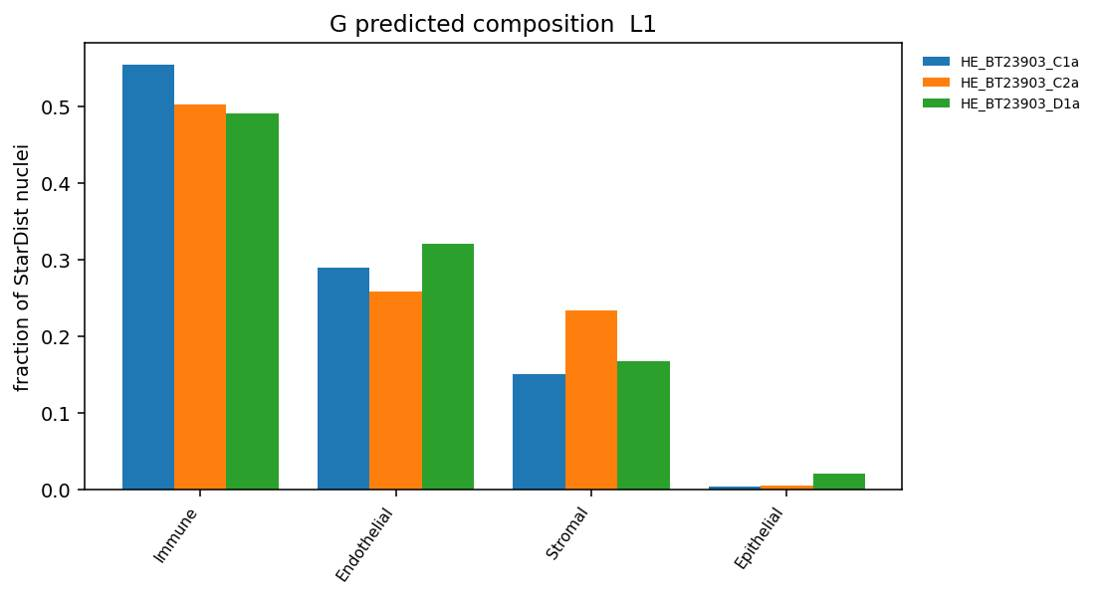

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/G_composition_L1.png

===== G L12 =====


fraction                                    mean_conf  \
sample      HE_BT23903_C1a HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a   
class                                                                     
T_cell               0.699          0.663          0.620          0.485   
Stromal              0.200          0.247          0.256          0.362   
Endothelial          0.056          0.051          0.051          0.342   
Myeloid              0.032          0.025          0.033          0.296   
B_Plasma             0.009          0.009          0.024          0.392   
Epithelial           0.003          0.003          0.013          0.339   
Tumor                0.002          0.002          0.004          0.360   

                                                       n                 \
sample      HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a HE_BT23903_C2a   
class                                                                     
T_cell               0.482          0.461        40326.0        40986.0   
Stromal              0.384          0.365        11543.0        15265.0   
Endothelial          0.344          0.326         3257.0         3161.0   
Myeloid              0.292          0.292         1835.0         1548.0   
B_Plasma             0.392          0.396          499.0          571.0   
Epithelial           0.373          0.392          156.0          178.0   
Tumor                0.357          0.381          107.0          130.0   

                            
sample      HE_BT23903_D1a  
class                       
T_cell             38013.0  
Stromal            15678.0  
Endothelial         3125.0  
Myeloid             2039.0  
B_Plasma            1465.0  
Epithelial           794.0  
Tumor                240.0

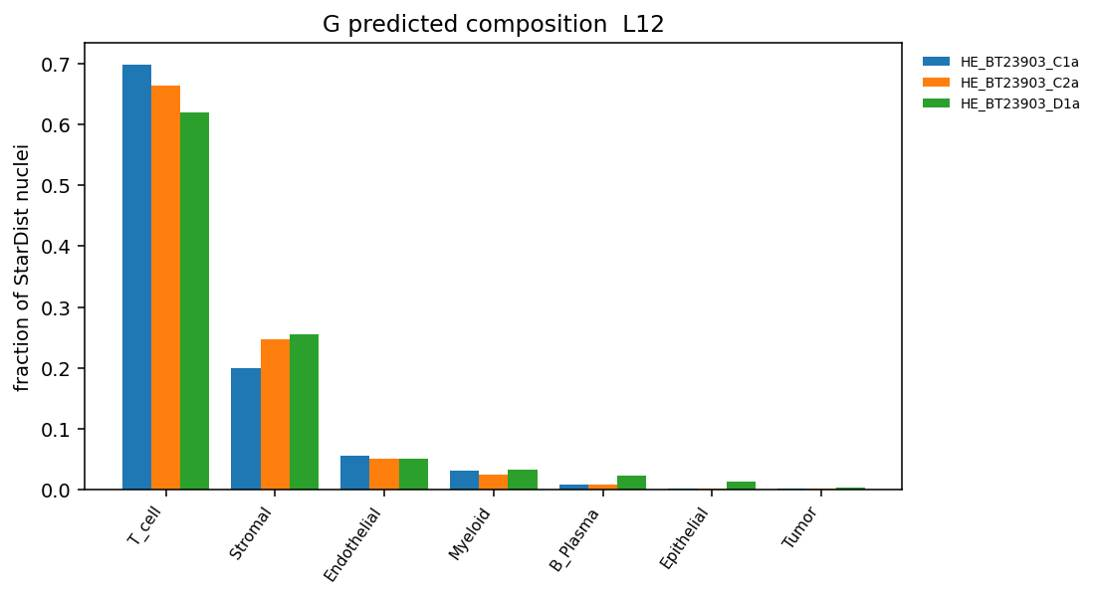

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/G_composition_L12.png

===== G L2 =====


fraction                                    mean_conf  \
sample            HE_BT23903_C1a HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a   
class                                                                           
B_cell                     0.385          0.357          0.418          0.343   
Fibroblast                 0.210          0.255          0.190          0.283   
CD4_T                      0.189          0.176          0.142          0.303   
Endothelial                0.150          0.143          0.171          0.286   
Neutrophil                 0.027          0.014          0.007          0.229   
Stromal                    0.016          0.026          0.027          0.299   
CD8_T                      0.009          0.009          0.019          0.254   
Tregs                      0.007          0.010          0.002          0.234   
Plasma                     0.002          0.004          0.006          0.228   
Injury_epithelial          0.001          0.001          0.005          0.267   
Epithelial                 0.001          0.001          0.004          0.224   
Tumor                      0.002          0.002          0.003          0.297   
DC                         0.000          0.001          0.001          0.220   
Myoepithelial              0.000          0.000          0.001          0.211   
DCIS                       0.000          0.000          0.001          0.251   
Macrophage                 0.000          0.000          0.000          0.127   
Alveolar                   0.000          0.000          0.000          0.225   
Myofibroblast              0.000          0.000          0.000          0.240   
NK                         0.000            NaN            NaN          0.195   

                                                             n                 \
sample            HE_BT23903_C2a HE_BT23903_D1a HE_BT23903_C1a HE_BT23903_C2a   
class                                                                           
B_cell                     0.341          0.364        22251.0        22056.0   
Fibroblast                 0.296          0.271        12113.0        15792.0   
CD4_T                      0.304          0.293        10923.0        10854.0   
Endothelial                0.285          0.268         8667.0         8852.0   
Neutrophil                 0.217          0.220         1576.0          876.0   
Stromal                    0.319          0.316          902.0         1624.0   
CD8_T                      0.241          0.246          541.0          581.0   
Tregs                      0.251          0.225          423.0          621.0   
Plasma                     0.243          0.268           93.0          258.0   
Injury_epithelial          0.272          0.280           69.0           46.0   
Epithelial                 0.238          0.248           32.0           83.0   
Tumor                      0.294          0.293           89.0          110.0   
DC                         0.231          0.248           16.0           33.0   
Myoepithelial              0.191          0.221           10.0           20.0   
DCIS                       0.233          0.294           13.0           16.0   
Macrophage                 0.198          0.178            1.0            9.0   
Alveolar                   0.188          0.203            2.0            2.0   
Myofibroblast              0.226          0.229            1.0            6.0   
NK                           NaN            NaN            1.0            NaN   

                                  
sample            HE_BT23903_D1a  
class                             
B_cell                   25642.0  
Fibroblast               11645.0  
CD4_T                     8729.0  
Endothelial              10515.0  
Neutrophil                 454.0  
Stromal                   1661.0  
CD8_T                     1195.0  
Tregs                       98.0  
Plasma                     392.0  
Injury_epithelial          321.0  
Epi

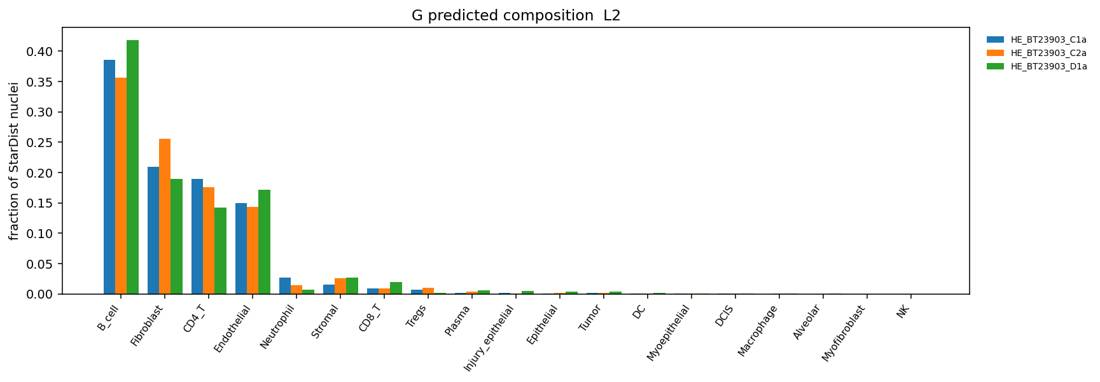

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/G_composition_L2.png
HE_BT23903_C1a


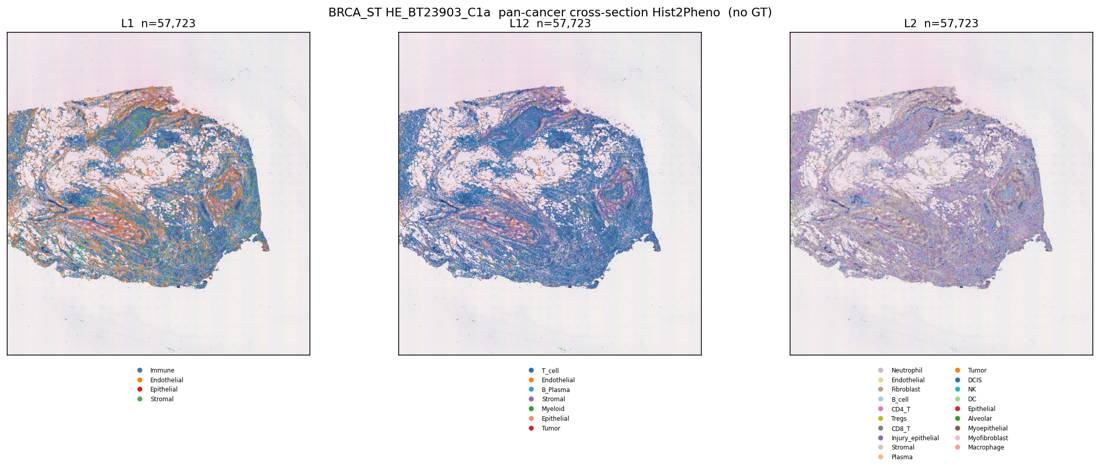

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C1a_spatial_L1_L12_L2.png
HE_BT23903_C2a


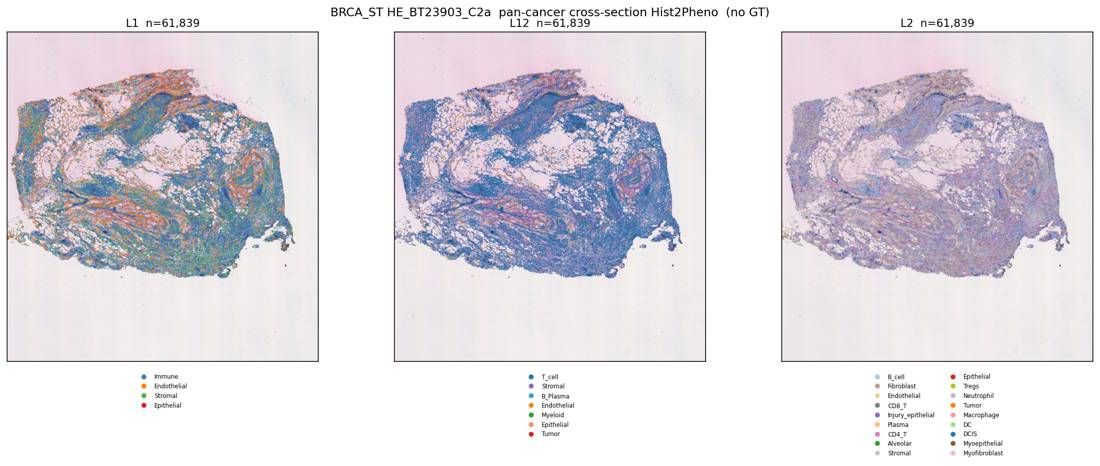

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C2a_spatial_L1_L12_L2.png
HE_BT23903_D1a


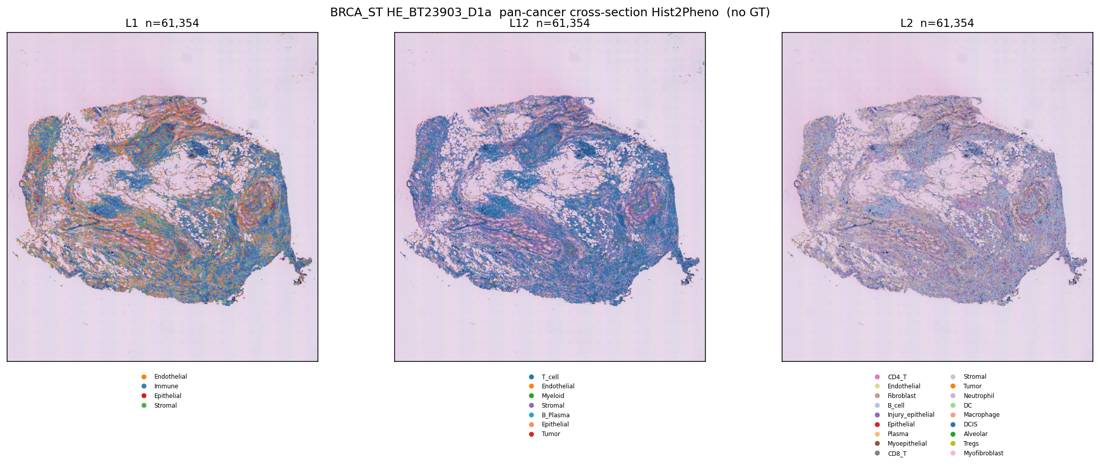

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_D1a_spatial_L1_L12_L2.png


In [2]:
missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )

display(Markdown(f"## {PATIENT} — composition and spatial labels"))
comp = composition_table(group)
for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {PATIENT} {head} =====")
    display(wide.round(3))

    classes = list(order)
    sections = list(dict.fromkeys(sub["sample"]))
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(classes) + 2), 4.4))
    x = range(len(classes))
    width = 0.8 / max(len(sections), 1)
    for i, section in enumerate(sections):
        ss = sub.loc[sub["sample"] == section].set_index("class")
        vals = [float(ss.loc[c, "fraction"]) if c in ss.index else 0.0 for c in classes]
        ax.bar([xi + i * width for xi in x], vals, width=width, label=section)
    ax.set_xticks([xi + width * (len(sections) - 1) / 2 for xi in x])
    ax.set_xticklabels(classes, rotation=55, ha="right", fontsize=8)
    ax.set_ylabel("fraction of StarDist nuclei")
    ax.set_title(f"{PATIENT} predicted composition  {head}")
    ax.legend(frameon=False, fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
    fig.tight_layout()
    if SAVE_FIGURES:
        out = fig_dir / f"{PATIENT}_composition_{head}.png"
        fig.savefig(out, dpi=DPI, bbox_inches="tight")
        print(out)
    display(fig)
    plt.close(fig)

for fig in plot_spatial(
    group,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz`.

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS. `spatial_HE` is native JPEG pixels, so R = **55 µm** uses this slide's own µm/px. TLS, SRI, and TNI are each a 1×3 row. This notebook embeds a resized preview; the saved PNG is full resolution.


In [3]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0
RECOMPUTE_NICHE = False

BRCA_ST_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca_st",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(group[0])["mpp_um"]),
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA_ST",
)
display(hni.index_formula_table(BRCA_ST_NICHE))


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


## G — TLS / SRI / TNI

[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23903_C1a/HE_BT23903_C1a_l2_probs.npz  (57723, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23903_C1a/HE_BT23903_C1a_niche_indices.h5ad  n=57,723
  TLS hotspot: {'n_cells_total': 57723, 'n_candidate_cells': 2887, 'fraction_candidate': 0.05001472549936767, 'max_tls_spatial': 0.20127900647846617, 'mean_tls_spatial_candidate': 0.1729438075697491, 'centroid_x': 4593.707795897038, 'centroid_y': 4709.662327583083}
  mean TLS=0.544  TLS_spatial=0.131  SRI=31.440  TNI=49.872
[probs] cache /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23903_C2a/HE_BT23903_C2a_l2_probs.npz  (61839, 20)
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/HE_BT23903_C2a/HE_BT23903_C2a_niche_indices.h5ad  n=61,839
  TLS hotspot: {'n_cells_total': 61839, 'n_candidate_cells': 3092, 'fraction

,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,HE_BT23903_C1a,57723,0.544,0.549,0.875,0.988,0.131,0.135,0.166,0.201,0.616,0.591,0.136,0.239,0.156,0.761
1,HE_BT23903_C2a,61839,0.536,0.538,0.878,0.991,0.131,0.135,0.167,0.210,0.604,0.579,0.143,0.250,0.157,0.748
2,HE_BT23903_D1a,61354,0.536,0.537,0.895,0.990,0.131,0.135,0.174,0.225,0.624,0.616,0.127,0.225,0.163,0.767


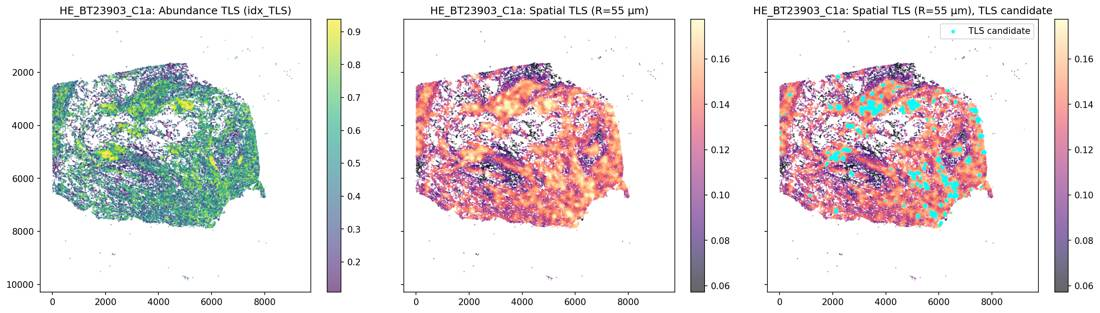

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C1a_TLS_abundance_vs_spatial.png


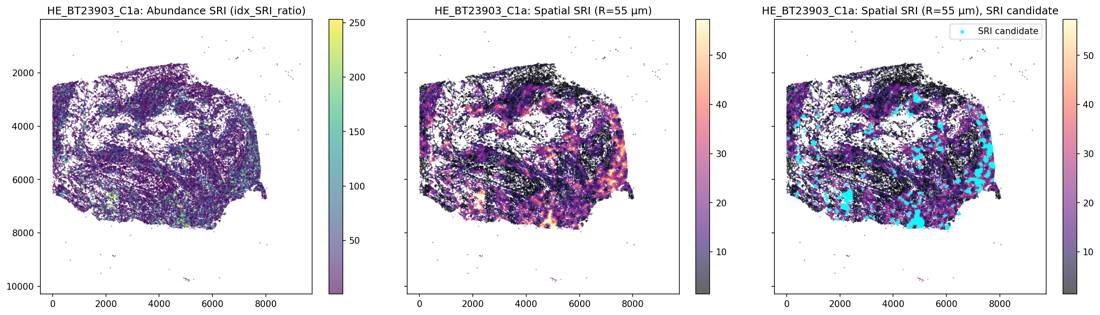

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C1a_SRI_abundance_vs_spatial.png


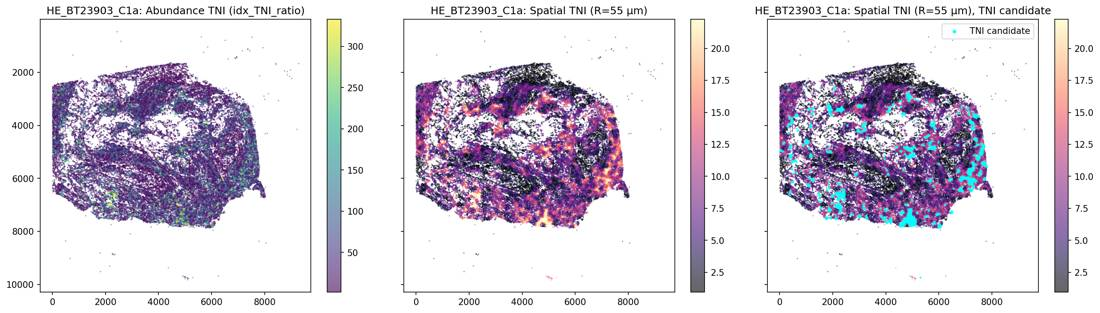

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C1a_TNI_abundance_vs_spatial.png


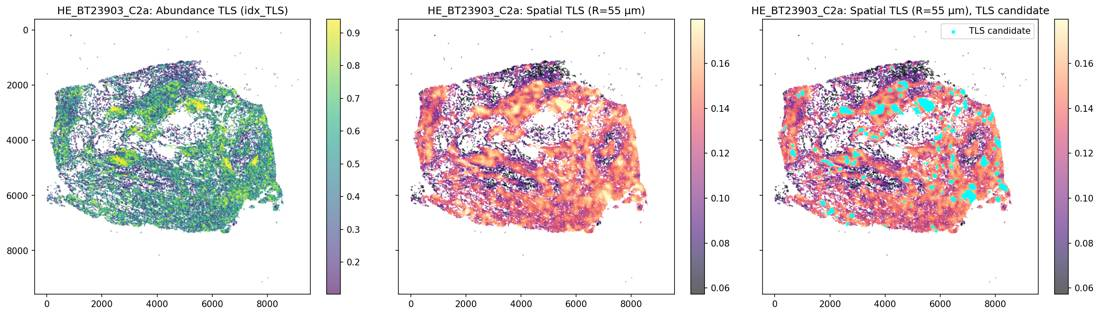

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C2a_TLS_abundance_vs_spatial.png


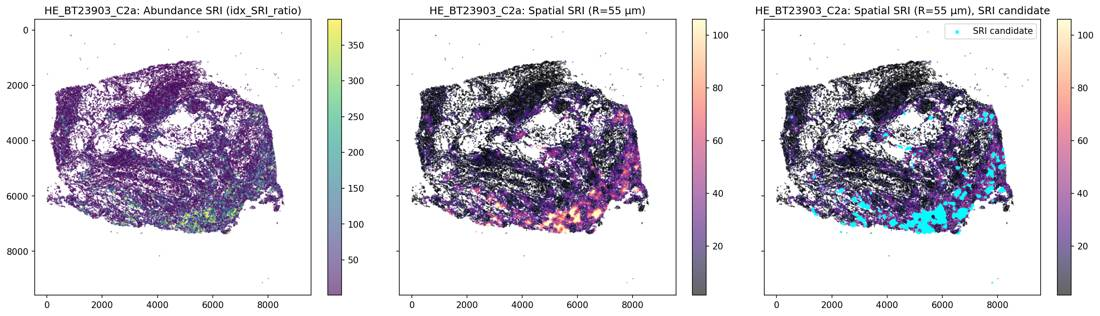

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C2a_SRI_abundance_vs_spatial.png


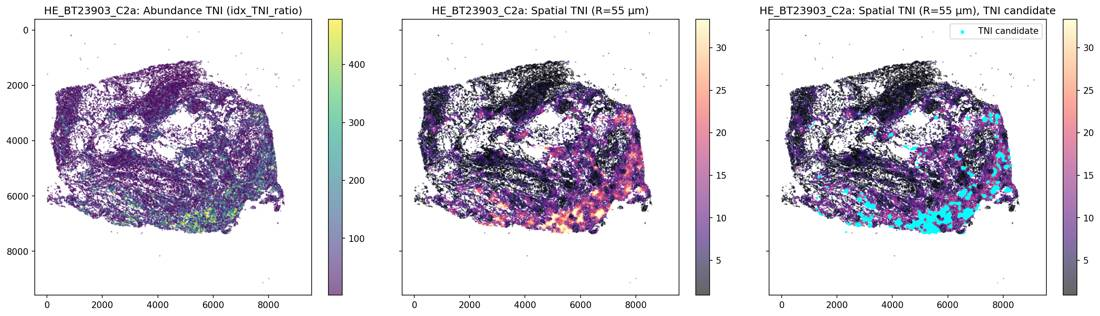

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_C2a_TNI_abundance_vs_spatial.png


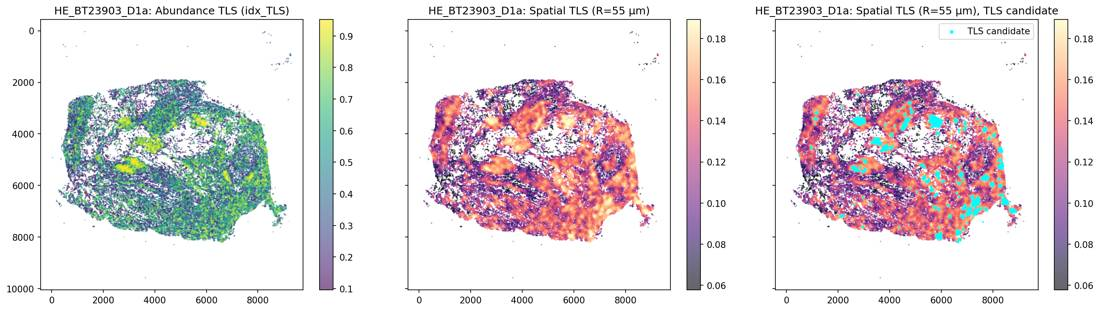

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_D1a_TLS_abundance_vs_spatial.png


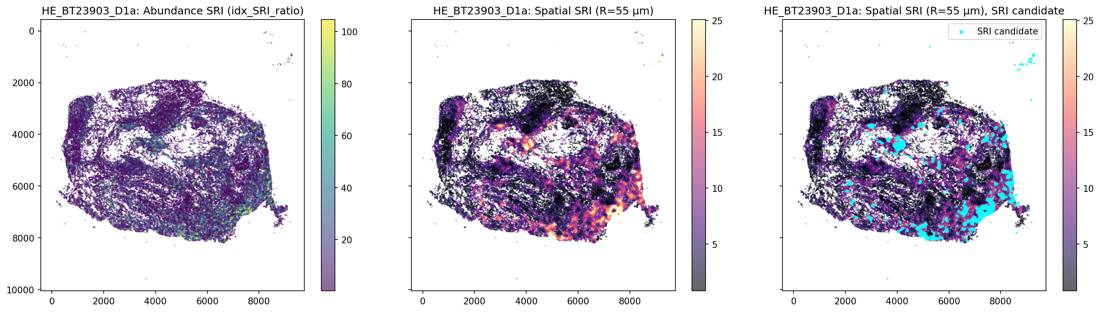

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_D1a_SRI_abundance_vs_spatial.png


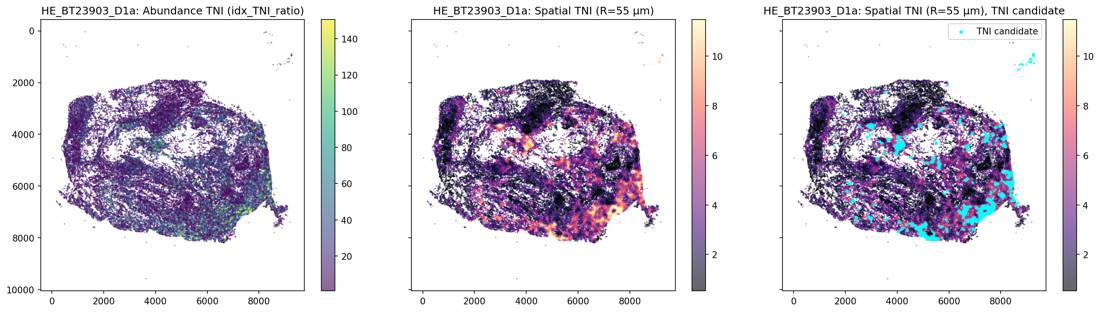

/nobackup2/users/lingyu/Python/Hist2Pheno/data/ST/BRCA/pred_pancancer_section/figures/HE_BT23903_D1a_TNI_abundance_vs_spatial.png


In [4]:
import numpy as np

missing = [s for s in group if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        f"No predictions yet for {PATIENT}: "
        + ", ".join(missing)
        + f". Run: SAMPLE={PATIENT} bash code/External_val/BRCA_ST/demo.sh all"
    )
display(Markdown(f"## {PATIENT} — TLS / SRI / TNI"))
frames = {}
for sample in group:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        absent = hni.missing_index_cell_types(class_names, BRCA_ST_NICHE)
        if absent:
            raise RuntimeError(f"{sample} missing niche compartments: {absent}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_ST_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_ST_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        out.write_h5ad(niche_path)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

def tls_score_row(df, sample: str) -> dict:
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }

tls_quant = pd.DataFrame([tls_score_row(df, sample) for sample, df in frames.items()])
tls_quant_path = fig_dir / f"tls_score_summary_{PATIENT}.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)
    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
